# MLT Assignment #1

Student: Aleksei Chekodanov, group J4133

Predict the biological response of a molecule ("Activity") from the `bioresponse.csv` dataset.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

### Data

In [2]:
bioresponse = pd.read_csv('bioresponse.csv', header=0, sep=',')
bioresponse.head()

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0


In [3]:
print(bioresponse.shape)
print('missing values:', bioresponse.isna().sum().sum())

(3751, 1777)
missing values: 0


In [4]:
y = bioresponse.Activity.values
X = bioresponse.iloc[:, 1:].values

print('Activity = 1: {:.2f}'.format(y.mean()))
print('Activity = 0: {:.2f}'.format(1 - y.mean()))

Activity = 1: 0.54
Activity = 0: 0.46


Classes are almost balanced. Split the data 75% / 25%:

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)
print(X_train.shape, X_test.shape)

(2813, 1776) (938, 1776)


### 1. Models

- small decision tree - `max_depth=3`
- deep decision tree - no depth limit
- random forest on small trees - `max_depth=3`
- random forest on deep trees - no depth limit

In [6]:
models = {
    'small tree': DecisionTreeClassifier(max_depth=3, random_state=1),
    'deep tree': DecisionTreeClassifier(random_state=1),
    'RF small trees': RandomForestClassifier(n_estimators=100, max_depth=3, random_state=1),
    'RF deep trees': RandomForestClassifier(n_estimators=100, random_state=1),
}

for name, model in models.items():
    model.fit(X_train, y_train)

print('depth of the deep tree:', models['deep tree'].get_depth())

depth of the deep tree: 33


### 2. Metrics

In [7]:
def get_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'precision': metrics.precision_score(y_true, pred),
        'recall': metrics.recall_score(y_true, pred),
        'accuracy': metrics.accuracy_score(y_true, pred),
        'f1': metrics.f1_score(y_true, pred),
        'log_loss': metrics.log_loss(y_true, proba),
    }

results = {}
probas = {}
for name, model in models.items():
    probas[name] = model.predict_proba(X_test)[:, 1]
    results[name] = get_metrics(y_test, probas[name])
    results[name]['train accuracy'] = model.score(X_train, y_train)

results = pd.DataFrame(results).T
results.round(3)

,precision,recall,accuracy,f1,log_loss,train accuracy
small tree,0.776,0.825,0.773,0.800,0.528,0.777
deep tree,0.741,0.732,0.712,0.736,10.375,1.000
RF small trees,0.726,0.767,0.713,0.746,0.593,0.735
RF deep trees,0.823,0.812,0.801,0.817,0.455,1.000


The deep tree has accuracy 1.0 on the train data but only ~0.71 on the test - it is overfitted.
Its log-loss is very large because a fully grown tree gives only probabilities 0 or 1, and every mistake made with probability 1 is penalized a lot.

### 3. Precision-recall and ROC curves

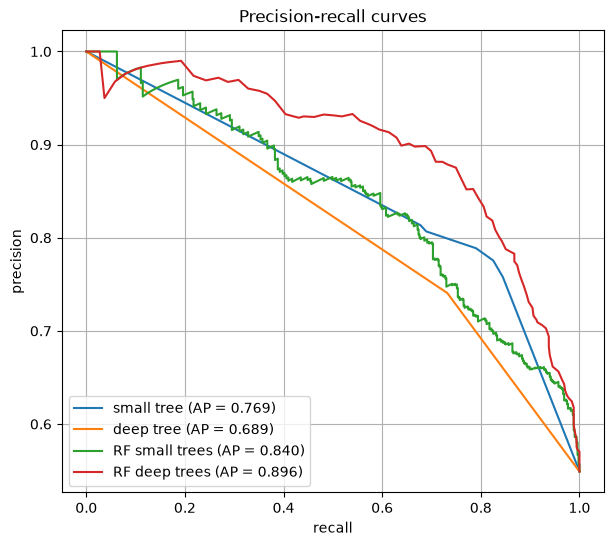

In [8]:
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    prec, rec, _ = metrics.precision_recall_curve(y_test, proba)
    ap = metrics.average_precision_score(y_test, proba)
    plt.plot(rec, prec, label='{} (AP = {:.3f})'.format(name, ap))
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('Precision-recall curves')
plt.grid(True)
plt.legend()
plt.show()

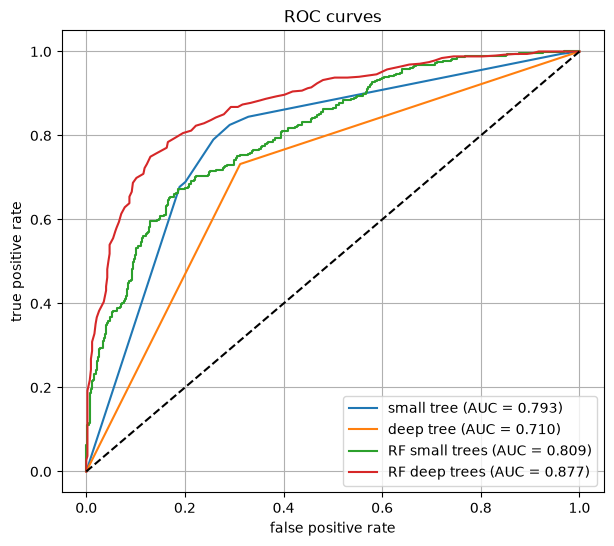

In [9]:
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, proba)
    auc = metrics.roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label='{} (AUC = {:.3f})'.format(name, auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('ROC curves')
plt.grid(True)
plt.legend()
plt.show()

The curves of the trees look like broken lines because a tree gives only a few different probability values (one per leaf).
Random forest on deep trees is the best model by all metrics.

### 4. Classifier that avoids Type II (False Negative) errors

We take the best model (random forest on deep trees) and lower the decision threshold:
a molecule is predicted as active already when its probability is lower than 0.5.

The threshold is chosen on the train data, not on the test. To get honest probabilities for the train objects, we use `cross_val_predict`
(each object gets a prediction from a model that did not see it). We take recall 0.98 on the train with a small reserve, because on new data recall is usually a bit lower.

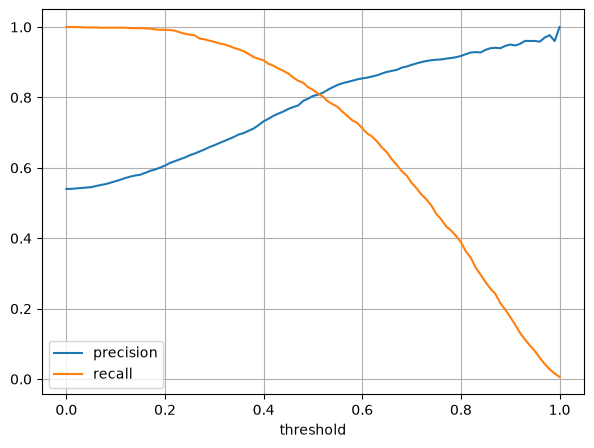

In [10]:
rf = RandomForestClassifier(n_estimators=100, random_state=1)
train_proba = cross_val_predict(rf, X_train, y_train, cv=5, method='predict_proba')[:, 1]

prec, rec, thresholds = metrics.precision_recall_curve(y_train, train_proba)

plt.figure(figsize=(7, 5))
plt.plot(thresholds, prec[:-1], label='precision')
plt.plot(thresholds, rec[:-1], label='recall')
plt.xlabel('threshold')
plt.grid(True)
plt.legend()
plt.show()

In [11]:
# the largest threshold with recall >= 0.98 on the train
threshold = thresholds[rec[:-1] >= 0.98].max()
print('threshold = {:.3f}'.format(threshold))

threshold = 0.240


In [12]:
proba = models['RF deep trees'].predict_proba(X_test)[:, 1]

results_fn = pd.DataFrame({
    'RF deep trees, threshold 0.5': get_metrics(y_test, proba, 0.5),
    'RF deep trees, threshold {:.2f}'.format(threshold): get_metrics(y_test, proba, threshold),
}).T
results_fn.round(3)

,precision,recall,accuracy,f1,log_loss
"RF deep trees, threshold 0.5",0.823,0.812,0.801,0.817,0.455
"RF deep trees, threshold 0.24",0.647,0.965,0.692,0.775,0.455


In [13]:
print('threshold 0.5:')
print(metrics.confusion_matrix(y_test, (proba >= 0.5).astype(int)))
print()
print('threshold {:.2f}:'.format(threshold))
print(metrics.confusion_matrix(y_test, (proba >= threshold).astype(int)))

threshold 0.5:
[[333  90]
 [ 97 418]]

threshold 0.24:
[[152 271]
 [ 18 497]]


Recall on the test data is now 0.965 > 0.95: the number of false negatives decreased from 97 to 18.
The price for it is more false positives, so precision and accuracy went down.
Log-loss did not change, because the model and its probabilities are the same - only the threshold is different.

### Conclusions

1. Random forest on deep trees is the best model: accuracy 0.801, F1 0.817, log-loss 0.455, ROC-AUC 0.877.
2. A single deep tree is overfitted (train accuracy 1.0, test accuracy 0.71) and has a huge log-loss. In a random forest many deep trees are averaged, so the variance goes down and the quality is much better.
3. Small trees do not overfit, but they are too simple. The random forest on small trees has a better ROC-AUC than one small tree (0.809 vs 0.793), but lower accuracy with threshold 0.5: its probabilities are close to 0.5, so the default threshold is not optimal for it.
4. To avoid False Negative errors we lowered the threshold of the best model to 0.24. Recall became 0.965, but precision dropped from 0.82 to 0.65 (271 false positives instead of 90). Such a model is useful when missing an active molecule is more expensive than checking an extra one.